In [43]:
# Student-specific parameters:

STUDENT_NAME = "CELO"
STUDENT_ID = "TUPM-26-1941"
color1 = "#7A0000"
color2 = "#FF0000"
color3 = "#000000"

print("Student:", STUDENT_NAME)
print("Student ID:", STUDENT_ID)
print("Bar Color 1:", color1)
print("Line Color 2:", color2)

Student: CELO
Student ID: TUPM-26-1941
Bar Color 1: #7A0000
Line Color 2: #FF0000


In [44]:
import pandas as pd
import os

dataset_path = r"C:\Users\admin\Lab8_Data_Visualization_Celo\spotify_dataset\spotify_top_1000_tracks.csv"

df = pd.read_csv(dataset_path, encoding="utf-8")

In [45]:
# Group the dataset by year and count songs released.
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')

df = df.dropna(subset=['release_date'])
df['year'] = df['release_date'].dt.year
year = df.groupby('year').size().sort_index()

In [46]:
# Calculate cumulative song count over years.
cumulative = year.cumsum()


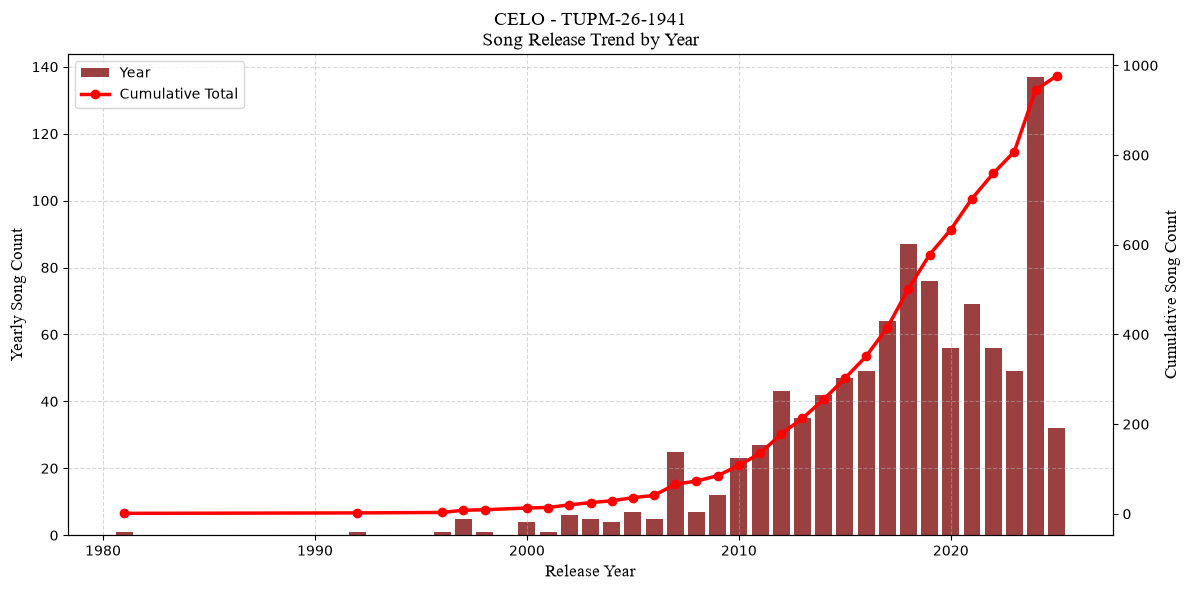

In [47]:
import matplotlib.pyplot as plt

# Bar Chart
fig, bg1 = plt.subplots(figsize=(12, 6))
bars = bg1.bar(year.index, year.values, color=color1, alpha=0.75, label='Year')
bg1.set_xlabel("Release Year", fontsize=12, fontname='Times New Roman')
bg1.set_ylabel("Yearly Song Count", color=color3, fontsize=12, fontname='Times New Roman')
bg1.tick_params(axis='y', labelcolor=color3)

# Line Chart
lg = bg1.twinx()
line = lg.plot(cumulative.index, cumulative.values, color=color2, marker='o', linewidth=2.5, label='Cumulative Total')
lg.set_ylabel("Cumulative Song Count", color=color3, fontsize=12, fontname='Times New Roman')
lg.tick_params(axis='y', labelcolor=color3)

# [OUTPUT] Plot yearly counts as bars and cumulative counts as a line on the same figure.
lines_1, labels_1 = bg1.get_legend_handles_labels()
lines_2, labels_2 = lg.get_legend_handles_labels()
bg1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.title(f"{STUDENT_NAME} - {STUDENT_ID}\nSong Release Trend by Year", fontsize=14, fontname='Times New Roman')
bg1.grid(True, linestyle='--', alpha=0.5)
fig.tight_layout()
plt.show()

